# EEGNet

Evaluating eegnet on Raw...
Processing Fold 1/5...
Processing Fold 2/5...
Processing Fold 3/5...
Processing Fold 4/5...
Processing Fold 5/5...


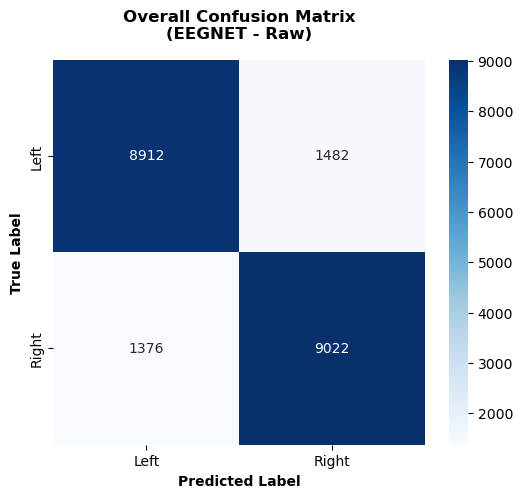

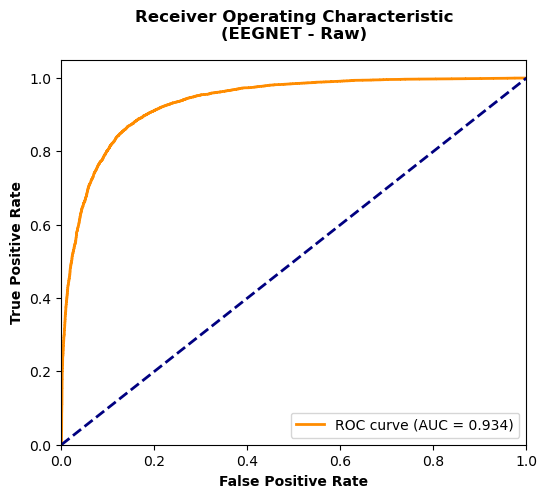

✅ Plots generated and saved successfully!


In [1]:
import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupKFold
from sklearn.metrics import confusion_matrix, roc_curve, auc
from tensorflow.keras.models import load_model
from tensorflow.keras.utils import Sequence

# =========================
# 1. Initial Settings
# =========================
DATASET_NAME = "Raw"
MODEL_PREFIX = "eegnet"
CSV_FILE = "dataset_metadata_raw.csv"
BATCH_SIZE = 32
N_CLASSES = 2

# =========================
# Data Generator
# =========================
class EEGGenerator(Sequence):
    def __init__(self, df, batch_size=32, shuffle=False):
        self.df = df.reset_index(drop=True)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indexes = np.arange(len(self.df))
        
    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch_size))
    
    def __getitem__(self, idx):
        batch_idx = self.indexes[idx * self.batch_size:(idx + 1) * self.batch_size]
        batch_df = self.df.iloc[batch_idx]
        X, y = [], []
        for _, row in batch_df.iterrows():
            data = np.load(row["file"])
            data = data.T
            data = data[:, :, np.newaxis]
            X.append(data)
            y.append(row["label"])
        X = np.array(X, dtype=np.float32)
        y = tf.keras.utils.to_categorical(y, N_CLASSES)
        return X, y

# =========================
# 2. Load Data and Apply GroupKFold
# =========================
df = pd.read_csv(CSV_FILE)
gkf = GroupKFold(n_splits=5)
groups = df["subject"]

all_y_true = []
all_y_pred_probs = []
all_y_pred_classes = []

print(f"Evaluating {MODEL_PREFIX} on {DATASET_NAME}...")

for fold, (train_idx, val_idx) in enumerate(gkf.split(df, df["label"], groups)):
    print(f"Processing Fold {fold + 1}/5...")
    val_df = df.iloc[val_idx]
    val_gen = EEGGenerator(val_df, BATCH_SIZE, shuffle=False)
    
    # Load the saved model
    model_path = f"models/{MODEL_PREFIX}_{DATASET_NAME}_fold{fold + 1}.h5"
    if not os.path.exists(model_path):
        print(f"⚠️ Error: Model file not found -> {model_path}")
        continue
        
    model = load_model(model_path)
    
    # Perform predictions
    for X_batch, y_batch in val_gen:
        preds = model.predict(X_batch, verbose=0)
        all_y_true.extend(np.argmax(y_batch, axis=1))
        all_y_pred_classes.extend(np.argmax(preds, axis=1))
        all_y_prob = preds[:, 1] # Probability of class 1 (Right Hand)
        all_y_pred_probs.extend(all_y_prob)
        
    del model
    tf.keras.backend.clear_session()
    gc.collect()

# =========================
# 3. Plot and Save Graphs
# =========================
os.makedirs("plots", exist_ok=True)

# ---- Confusion Matrix ----
cm = confusion_matrix(all_y_true, all_y_pred_classes)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Left', 'Right'], yticklabels=['Left', 'Right'])
plt.title(f'Overall Confusion Matrix\n({MODEL_PREFIX.upper()} - {DATASET_NAME})', pad=15, fontsize=12, fontweight='bold')
plt.ylabel('True Label', fontweight='bold')
plt.xlabel('Predicted Label', fontweight='bold')
plt.savefig(f'plots/CM_{MODEL_PREFIX}_{DATASET_NAME}.png', dpi=300, bbox_inches='tight')
plt.show()

# ---- ROC Curve ----
fpr, tpr, thresholds = roc_curve(all_y_true, all_y_pred_probs)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontweight='bold')
plt.ylabel('True Positive Rate', fontweight='bold')
plt.title(f'Receiver Operating Characteristic\n({MODEL_PREFIX.upper()} - {DATASET_NAME})', pad=15, fontsize=12, fontweight='bold')
plt.legend(loc="lower right")
plt.savefig(f'plots/ROC_{MODEL_PREFIX}_{DATASET_NAME}.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Plots generated and saved successfully!")

Evaluating eegnet on Filtered_8_30Hz...
Processing Fold 1/5...
Processing Fold 2/5...
Processing Fold 3/5...
Processing Fold 4/5...
Processing Fold 5/5...


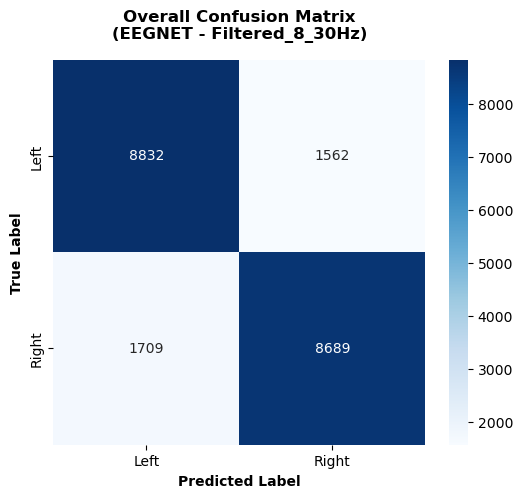

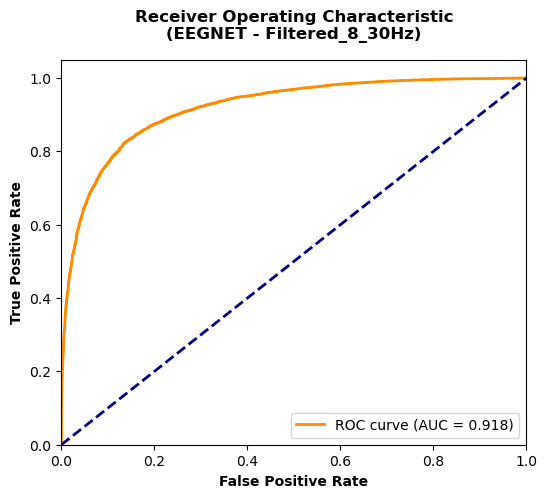

✅ Plots generated and saved successfully!


In [1]:
import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupKFold
from sklearn.metrics import confusion_matrix, roc_curve, auc
from tensorflow.keras.models import load_model
from tensorflow.keras.utils import Sequence

# =========================
# 1. Initial Settings
# =========================
DATASET_NAME = "Filtered_8_30Hz"
MODEL_PREFIX = "eegnet"
CSV_FILE = "dataset_metadata_filtered.csv"
BATCH_SIZE = 32
N_CLASSES = 2

# =========================
# Data Generator
# =========================
class EEGGenerator(Sequence):
    def __init__(self, df, batch_size=32, shuffle=False):
        self.df = df.reset_index(drop=True)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indexes = np.arange(len(self.df))
        
    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch_size))
    
    def __getitem__(self, idx):
        batch_idx = self.indexes[idx * self.batch_size:(idx + 1) * self.batch_size]
        batch_df = self.df.iloc[batch_idx]
        X, y = [], []
        for _, row in batch_df.iterrows():
            data = np.load(row["file"])
            data = data.T
            data = data[:, :, np.newaxis]
            X.append(data)
            y.append(row["label"])
        X = np.array(X, dtype=np.float32)
        y = tf.keras.utils.to_categorical(y, N_CLASSES)
        return X, y

# =========================
# 2. Load Data and Apply GroupKFold
# =========================
df = pd.read_csv(CSV_FILE)
gkf = GroupKFold(n_splits=5)
groups = df["subject"]

all_y_true = []
all_y_pred_probs = []
all_y_pred_classes = []

print(f"Evaluating {MODEL_PREFIX} on {DATASET_NAME}...")

for fold, (train_idx, val_idx) in enumerate(gkf.split(df, df["label"], groups)):
    print(f"Processing Fold {fold + 1}/5...")
    val_df = df.iloc[val_idx]
    val_gen = EEGGenerator(val_df, BATCH_SIZE, shuffle=False)
    
    # Load the saved model
    model_path = f"models/{MODEL_PREFIX}_{DATASET_NAME}_fold{fold + 1}.h5"
    if not os.path.exists(model_path):
        print(f"⚠️ Error: Model file not found -> {model_path}")
        continue
        
    model = load_model(model_path)
    
    # Perform predictions
    for X_batch, y_batch in val_gen:
        preds = model.predict(X_batch, verbose=0)
        all_y_true.extend(np.argmax(y_batch, axis=1))
        all_y_pred_classes.extend(np.argmax(preds, axis=1))
        all_y_prob = preds[:, 1] # Probability of class 1 (Right Hand)
        all_y_pred_probs.extend(all_y_prob)
        
    del model
    tf.keras.backend.clear_session()
    gc.collect()

# =========================
# 3. Plot and Save Graphs
# =========================
os.makedirs("plots", exist_ok=True)

# ---- Confusion Matrix ----
cm = confusion_matrix(all_y_true, all_y_pred_classes)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Left', 'Right'], yticklabels=['Left', 'Right'])
plt.title(f'Overall Confusion Matrix\n({MODEL_PREFIX.upper()} - {DATASET_NAME})', pad=15, fontsize=12, fontweight='bold')
plt.ylabel('True Label', fontweight='bold')
plt.xlabel('Predicted Label', fontweight='bold')
plt.savefig(f'plots/CM_{MODEL_PREFIX}_{DATASET_NAME}.png', dpi=300, bbox_inches='tight')
plt.show()

# ---- ROC Curve ----
fpr, tpr, thresholds = roc_curve(all_y_true, all_y_pred_probs)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontweight='bold')
plt.ylabel('True Positive Rate', fontweight='bold')
plt.title(f'Receiver Operating Characteristic\n({MODEL_PREFIX.upper()} - {DATASET_NAME})', pad=15, fontsize=12, fontweight='bold')
plt.legend(loc="lower right")
plt.savefig(f'plots/ROC_{MODEL_PREFIX}_{DATASET_NAME}.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Plots generated and saved successfully!")

Evaluating eegnet on Filtered_8_13Hz...
Processing Fold 1/5...
Processing Fold 2/5...
Processing Fold 3/5...
Processing Fold 4/5...
Processing Fold 5/5...


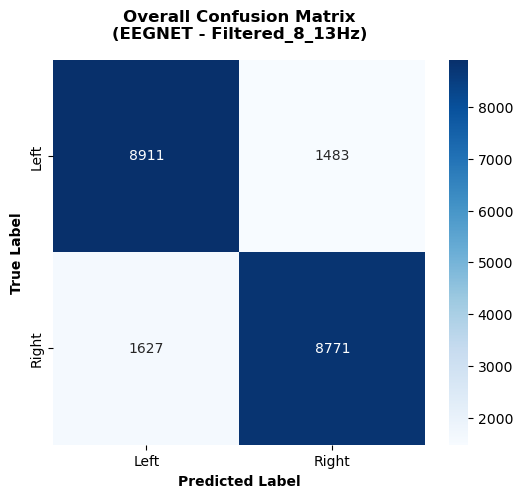

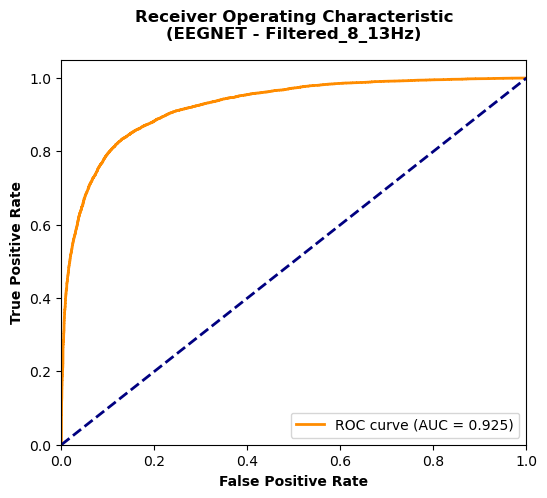

✅ Plots generated and saved successfully!


In [1]:
import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupKFold
from sklearn.metrics import confusion_matrix, roc_curve, auc
from tensorflow.keras.models import load_model
from tensorflow.keras.utils import Sequence

# =========================
# 1. Initial Settings
# =========================
DATASET_NAME = "Filtered_8_13Hz"
MODEL_PREFIX = "eegnet"
CSV_FILE = "dataset_metadata_8_13Hz.csv"
BATCH_SIZE = 32
N_CLASSES = 2

# =========================
# Data Generator
# =========================
class EEGGenerator(Sequence):
    def __init__(self, df, batch_size=32, shuffle=False):
        self.df = df.reset_index(drop=True)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indexes = np.arange(len(self.df))
        
    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch_size))
    
    def __getitem__(self, idx):
        batch_idx = self.indexes[idx * self.batch_size:(idx + 1) * self.batch_size]
        batch_df = self.df.iloc[batch_idx]
        X, y = [], []
        for _, row in batch_df.iterrows():
            data = np.load(row["file"])
            data = data.T
            data = data[:, :, np.newaxis]
            X.append(data)
            y.append(row["label"])
        X = np.array(X, dtype=np.float32)
        y = tf.keras.utils.to_categorical(y, N_CLASSES)
        return X, y

# =========================
# 2. Load Data and Apply GroupKFold
# =========================
df = pd.read_csv(CSV_FILE)
gkf = GroupKFold(n_splits=5)
groups = df["subject"]

all_y_true = []
all_y_pred_probs = []
all_y_pred_classes = []

print(f"Evaluating {MODEL_PREFIX} on {DATASET_NAME}...")

for fold, (train_idx, val_idx) in enumerate(gkf.split(df, df["label"], groups)):
    print(f"Processing Fold {fold + 1}/5...")
    val_df = df.iloc[val_idx]
    val_gen = EEGGenerator(val_df, BATCH_SIZE, shuffle=False)
    
    # Load the saved model
    model_path = f"models/{MODEL_PREFIX}_{DATASET_NAME}_fold{fold + 1}.h5"
    if not os.path.exists(model_path):
        print(f"⚠️ Error: Model file not found -> {model_path}")
        continue
        
    model = load_model(model_path)
    
    # Perform predictions
    for X_batch, y_batch in val_gen:
        preds = model.predict(X_batch, verbose=0)
        all_y_true.extend(np.argmax(y_batch, axis=1))
        all_y_pred_classes.extend(np.argmax(preds, axis=1))
        all_y_prob = preds[:, 1] # Probability of class 1 (Right Hand)
        all_y_pred_probs.extend(all_y_prob)
        
    del model
    tf.keras.backend.clear_session()
    gc.collect()

# =========================
# 3. Plot and Save Graphs
# =========================
os.makedirs("plots", exist_ok=True)

# ---- Confusion Matrix ----
cm = confusion_matrix(all_y_true, all_y_pred_classes)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Left', 'Right'], yticklabels=['Left', 'Right'])
plt.title(f'Overall Confusion Matrix\n({MODEL_PREFIX.upper()} - {DATASET_NAME})', pad=15, fontsize=12, fontweight='bold')
plt.ylabel('True Label', fontweight='bold')
plt.xlabel('Predicted Label', fontweight='bold')
plt.savefig(f'plots/CM_{MODEL_PREFIX}_{DATASET_NAME}.png', dpi=300, bbox_inches='tight')
plt.show()

# ---- ROC Curve ----
fpr, tpr, thresholds = roc_curve(all_y_true, all_y_pred_probs)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontweight='bold')
plt.ylabel('True Positive Rate', fontweight='bold')
plt.title(f'Receiver Operating Characteristic\n({MODEL_PREFIX.upper()} - {DATASET_NAME})', pad=15, fontsize=12, fontweight='bold')
plt.legend(loc="lower right")
plt.savefig(f'plots/ROC_{MODEL_PREFIX}_{DATASET_NAME}.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Plots generated and saved successfully!")

# CvT

Evaluating CVT on Raw...
Processing Fold 1/5...
Processing Fold 2/5...
Processing Fold 3/5...
Processing Fold 4/5...
Processing Fold 5/5...


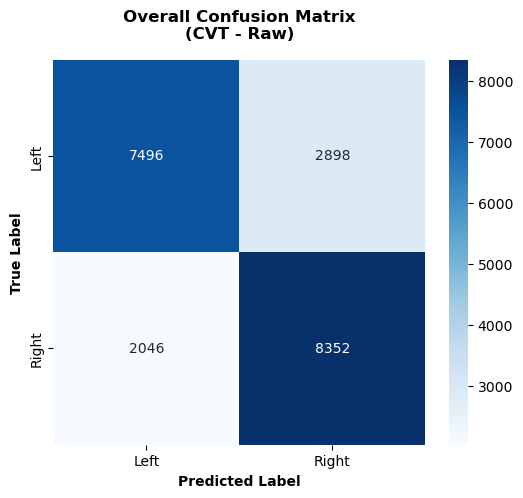

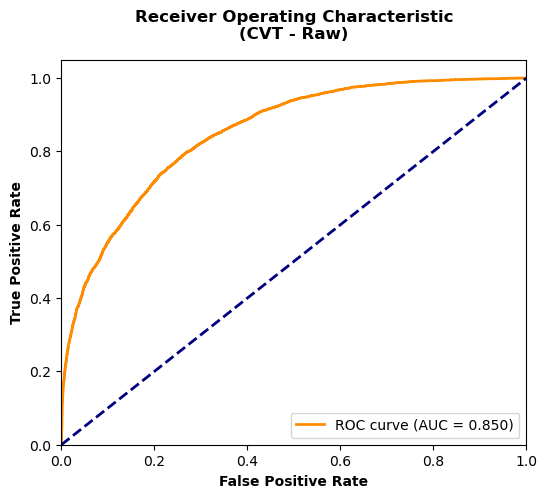

✅ Plots generated and saved successfully!


In [2]:
import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupKFold
from sklearn.metrics import confusion_matrix, roc_curve, auc
from tensorflow.keras.models import load_model
from tensorflow.keras.utils import Sequence
from tensorflow.keras.layers import Layer

# =========================
# 1. Initial Settings
# =========================
DATASET_NAME = "Raw" 
CSV_FILE = "dataset_metadata_raw.csv"

MODEL_PREFIX = "cvt"
BATCH_SIZE = 32
N_CLASSES = 2
SEQ_LEN = 2560
CHANNELS = 27

# =========================
# 2. Custom Layers for CvT (Crucial for load_model)
# =========================
class Patches(Layer):
    def __init__(self, patch_size, **kwargs):
        super().__init__(**kwargs)
        self.patch_size = patch_size

    def call(self, signals):
        batch_size = tf.shape(signals)[0]
        patches = tf.reshape(
            signals,
            [batch_size, -1, self.patch_size, tf.shape(signals)[-1]]
        )
        return patches

    def get_config(self):
        config = super().get_config()
        config.update({"patch_size": self.patch_size})
        return config

def get_sinusoidal_position_embedding(sequence_length, dim):
    position = np.arange(sequence_length)[:, np.newaxis]
    div_term = np.exp(np.arange(0, dim, 2) * -(np.log(10000.0) / dim))
    pe = np.zeros((sequence_length, dim))
    pe[:, 0::2] = np.sin(position * div_term)
    pe[:, 1::2] = np.cos(position * div_term)
    return tf.constant(pe, dtype=tf.float32)

class SinusoidalPositionEmbedding(Layer):
    def __init__(self, sequence_length, dim, **kwargs):
        super().__init__(**kwargs)
        self.sequence_length = sequence_length
        self.dim = dim
        self.pos_embedding = get_sinusoidal_position_embedding(sequence_length, dim)

    def call(self, x):
        return x + self.pos_embedding

    def get_config(self):
        config = super().get_config()
        config.update({
            "sequence_length": self.sequence_length,
            "dim": self.dim,
        })
        return config

# =========================
# 3. Data Generator (Shape: 2560, 27)
# =========================
class EEGGenerator_CvT(Sequence):
    def __init__(self, df, batch_size=32, shuffle=False):
        self.df = df.reset_index(drop=True)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indexes = np.arange(len(self.df))
        
    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch_size))
    
    def __getitem__(self, idx):
        batch_idx = self.indexes[idx * self.batch_size:(idx + 1) * self.batch_size]
        batch_df = self.df.iloc[batch_idx]
        
        X, y = [], []
        for _, row in batch_df.iterrows():
            data = np.load(row["file"])
            # Handle shape dynamically for CvT
            if data.shape == (CHANNELS, SEQ_LEN):
                data = data.T
            X.append(data)
            y.append(row["label"])
            
        X = np.array(X, dtype=np.float32)
        y = tf.keras.utils.to_categorical(y, N_CLASSES)
        return X, y

# =========================
# 4. Load Data and Apply GroupKFold
# =========================
df = pd.read_csv(CSV_FILE)
gkf = GroupKFold(n_splits=5)
groups = df["subject"]

all_y_true = []
all_y_pred_probs = []
all_y_pred_classes = []

print(f"Evaluating {MODEL_PREFIX.upper()} on {DATASET_NAME}...")

for fold, (train_idx, val_idx) in enumerate(gkf.split(df, df["label"], groups)):
    print(f"Processing Fold {fold + 1}/5...")
    val_df = df.iloc[val_idx]
    val_gen = EEGGenerator_CvT(val_df, BATCH_SIZE, shuffle=False)
    
    model_path = f"models/{MODEL_PREFIX}_{DATASET_NAME}_fold{fold + 1}.h5"
    if not os.path.exists(model_path):
        print(f"⚠️ Error: Model file not found -> {model_path}")
        continue
        
    # ✅ Load model with Custom Objects
    model = load_model(
        model_path, 
        custom_objects={
            'Patches': Patches, 
            'SinusoidalPositionEmbedding': SinusoidalPositionEmbedding
        }
    )
    
    # Perform predictions
    for X_batch, y_batch in val_gen:
        preds = model.predict(X_batch, verbose=0)
        all_y_true.extend(np.argmax(y_batch, axis=1))
        all_y_pred_classes.extend(np.argmax(preds, axis=1))
        all_y_prob = preds[:, 1] # Probability of class 1
        all_y_pred_probs.extend(all_y_prob)
        
    del model
    tf.keras.backend.clear_session()
    gc.collect()

# =========================
# 5. Plot and Save Graphs
# =========================
os.makedirs("plots", exist_ok=True)

# ---- Confusion Matrix ----
cm = confusion_matrix(all_y_true, all_y_pred_classes)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Left', 'Right'], yticklabels=['Left', 'Right'])
plt.title(f'Overall Confusion Matrix\n({MODEL_PREFIX.upper()} - {DATASET_NAME})', pad=15, fontsize=12, fontweight='bold')
plt.ylabel('True Label', fontweight='bold')
plt.xlabel('Predicted Label', fontweight='bold')
plt.savefig(f'plots/CM_{MODEL_PREFIX}_{DATASET_NAME}.png', dpi=300, bbox_inches='tight')
plt.show()

# ---- ROC Curve ----
fpr, tpr, thresholds = roc_curve(all_y_true, all_y_pred_probs)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontweight='bold')
plt.ylabel('True Positive Rate', fontweight='bold')
plt.title(f'Receiver Operating Characteristic\n({MODEL_PREFIX.upper()} - {DATASET_NAME})', pad=15, fontsize=12, fontweight='bold')
plt.legend(loc="lower right")
plt.savefig(f'plots/ROC_{MODEL_PREFIX}_{DATASET_NAME}.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Plots generated and saved successfully!")

Evaluating CVT on Filtered_8_30Hz...
Processing Fold 1/5...
Processing Fold 2/5...
Processing Fold 3/5...
Processing Fold 4/5...
Processing Fold 5/5...


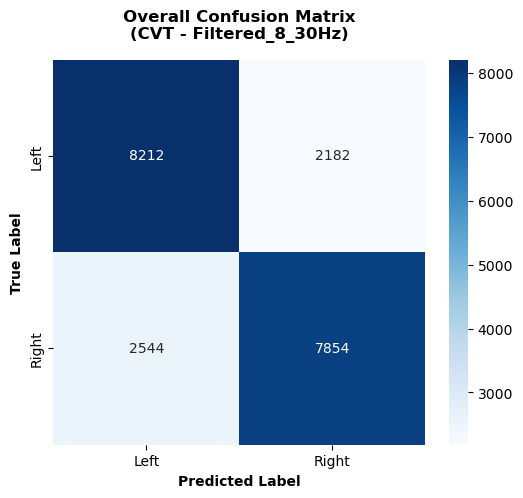

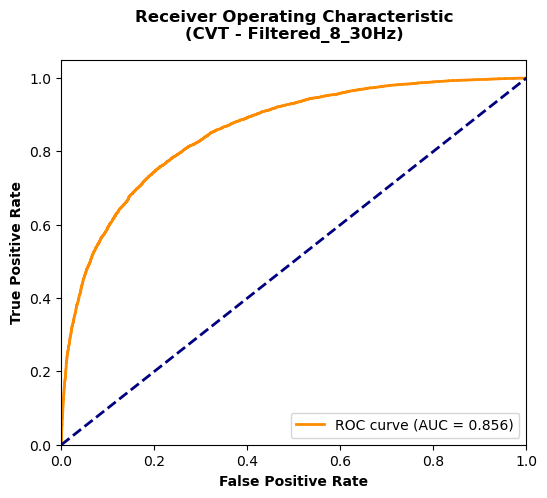

✅ Plots generated and saved successfully!


In [3]:
import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupKFold
from sklearn.metrics import confusion_matrix, roc_curve, auc
from tensorflow.keras.models import load_model
from tensorflow.keras.utils import Sequence
from tensorflow.keras.layers import Layer

# =========================
# 1. Initial Settings
# =========================
DATASET_NAME = "Filtered_8_30Hz" 
CSV_FILE = "dataset_metadata_filtered.csv"

MODEL_PREFIX = "cvt"
BATCH_SIZE = 32
N_CLASSES = 2
SEQ_LEN = 2560
CHANNELS = 27

# =========================
# 2. Custom Layers for CvT (Crucial for load_model)
# =========================
class Patches(Layer):
    def __init__(self, patch_size, **kwargs):
        super().__init__(**kwargs)
        self.patch_size = patch_size

    def call(self, signals):
        batch_size = tf.shape(signals)[0]
        patches = tf.reshape(
            signals,
            [batch_size, -1, self.patch_size, tf.shape(signals)[-1]]
        )
        return patches

    def get_config(self):
        config = super().get_config()
        config.update({"patch_size": self.patch_size})
        return config

def get_sinusoidal_position_embedding(sequence_length, dim):
    position = np.arange(sequence_length)[:, np.newaxis]
    div_term = np.exp(np.arange(0, dim, 2) * -(np.log(10000.0) / dim))
    pe = np.zeros((sequence_length, dim))
    pe[:, 0::2] = np.sin(position * div_term)
    pe[:, 1::2] = np.cos(position * div_term)
    return tf.constant(pe, dtype=tf.float32)

class SinusoidalPositionEmbedding(Layer):
    def __init__(self, sequence_length, dim, **kwargs):
        super().__init__(**kwargs)
        self.sequence_length = sequence_length
        self.dim = dim
        self.pos_embedding = get_sinusoidal_position_embedding(sequence_length, dim)

    def call(self, x):
        return x + self.pos_embedding

    def get_config(self):
        config = super().get_config()
        config.update({
            "sequence_length": self.sequence_length,
            "dim": self.dim,
        })
        return config

# =========================
# 3. Data Generator (Shape: 2560, 27)
# =========================
class EEGGenerator_CvT(Sequence):
    def __init__(self, df, batch_size=32, shuffle=False):
        self.df = df.reset_index(drop=True)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indexes = np.arange(len(self.df))
        
    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch_size))
    
    def __getitem__(self, idx):
        batch_idx = self.indexes[idx * self.batch_size:(idx + 1) * self.batch_size]
        batch_df = self.df.iloc[batch_idx]
        
        X, y = [], []
        for _, row in batch_df.iterrows():
            data = np.load(row["file"])
            # Handle shape dynamically for CvT
            if data.shape == (CHANNELS, SEQ_LEN):
                data = data.T
            X.append(data)
            y.append(row["label"])
            
        X = np.array(X, dtype=np.float32)
        y = tf.keras.utils.to_categorical(y, N_CLASSES)
        return X, y

# =========================
# 4. Load Data and Apply GroupKFold
# =========================
df = pd.read_csv(CSV_FILE)
gkf = GroupKFold(n_splits=5)
groups = df["subject"]

all_y_true = []
all_y_pred_probs = []
all_y_pred_classes = []

print(f"Evaluating {MODEL_PREFIX.upper()} on {DATASET_NAME}...")

for fold, (train_idx, val_idx) in enumerate(gkf.split(df, df["label"], groups)):
    print(f"Processing Fold {fold + 1}/5...")
    val_df = df.iloc[val_idx]
    val_gen = EEGGenerator_CvT(val_df, BATCH_SIZE, shuffle=False)
    
    model_path = f"models/{MODEL_PREFIX}_{DATASET_NAME}_fold{fold + 1}.h5"
    if not os.path.exists(model_path):
        print(f"⚠️ Error: Model file not found -> {model_path}")
        continue
        
    # ✅ Load model with Custom Objects
    model = load_model(
        model_path, 
        custom_objects={
            'Patches': Patches, 
            'SinusoidalPositionEmbedding': SinusoidalPositionEmbedding
        }
    )
    
    # Perform predictions
    for X_batch, y_batch in val_gen:
        preds = model.predict(X_batch, verbose=0)
        all_y_true.extend(np.argmax(y_batch, axis=1))
        all_y_pred_classes.extend(np.argmax(preds, axis=1))
        all_y_prob = preds[:, 1] # Probability of class 1
        all_y_pred_probs.extend(all_y_prob)
        
    del model
    tf.keras.backend.clear_session()
    gc.collect()

# =========================
# 5. Plot and Save Graphs
# =========================
os.makedirs("plots", exist_ok=True)

# ---- Confusion Matrix ----
cm = confusion_matrix(all_y_true, all_y_pred_classes)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Left', 'Right'], yticklabels=['Left', 'Right'])
plt.title(f'Overall Confusion Matrix\n({MODEL_PREFIX.upper()} - {DATASET_NAME})', pad=15, fontsize=12, fontweight='bold')
plt.ylabel('True Label', fontweight='bold')
plt.xlabel('Predicted Label', fontweight='bold')
plt.savefig(f'plots/CM_{MODEL_PREFIX}_{DATASET_NAME}.png', dpi=300, bbox_inches='tight')
plt.show()

# ---- ROC Curve ----
fpr, tpr, thresholds = roc_curve(all_y_true, all_y_pred_probs)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontweight='bold')
plt.ylabel('True Positive Rate', fontweight='bold')
plt.title(f'Receiver Operating Characteristic\n({MODEL_PREFIX.upper()} - {DATASET_NAME})', pad=15, fontsize=12, fontweight='bold')
plt.legend(loc="lower right")
plt.savefig(f'plots/ROC_{MODEL_PREFIX}_{DATASET_NAME}.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Plots generated and saved successfully!")

Evaluating CVT on Filtered_8_13Hz...
Processing Fold 1/5...
Processing Fold 2/5...
Processing Fold 3/5...
Processing Fold 4/5...
Processing Fold 5/5...


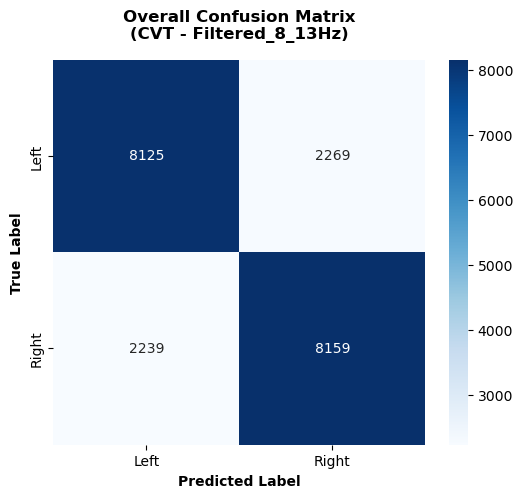

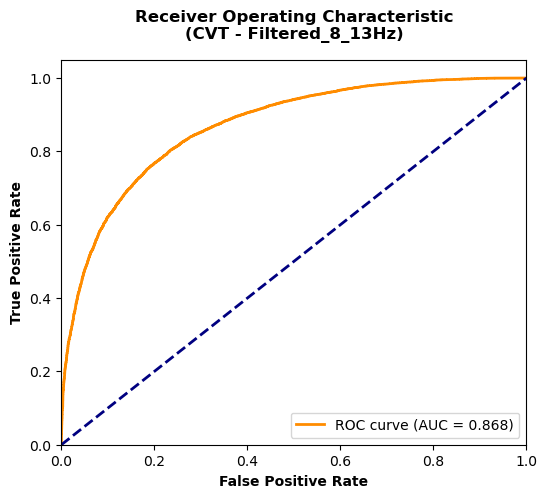

✅ Plots generated and saved successfully!


In [4]:
import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupKFold
from sklearn.metrics import confusion_matrix, roc_curve, auc
from tensorflow.keras.models import load_model
from tensorflow.keras.utils import Sequence
from tensorflow.keras.layers import Layer

# =========================
# 1. Initial Settings
# =========================
DATASET_NAME = "Filtered_8_13Hz" 
CSV_FILE = "dataset_metadata_8_13Hz.csv"

MODEL_PREFIX = "cvt"
BATCH_SIZE = 32
N_CLASSES = 2
SEQ_LEN = 2560
CHANNELS = 27

# =========================
# 2. Custom Layers for CvT (Crucial for load_model)
# =========================
class Patches(Layer):
    def __init__(self, patch_size, **kwargs):
        super().__init__(**kwargs)
        self.patch_size = patch_size

    def call(self, signals):
        batch_size = tf.shape(signals)[0]
        patches = tf.reshape(
            signals,
            [batch_size, -1, self.patch_size, tf.shape(signals)[-1]]
        )
        return patches

    def get_config(self):
        config = super().get_config()
        config.update({"patch_size": self.patch_size})
        return config

def get_sinusoidal_position_embedding(sequence_length, dim):
    position = np.arange(sequence_length)[:, np.newaxis]
    div_term = np.exp(np.arange(0, dim, 2) * -(np.log(10000.0) / dim))
    pe = np.zeros((sequence_length, dim))
    pe[:, 0::2] = np.sin(position * div_term)
    pe[:, 1::2] = np.cos(position * div_term)
    return tf.constant(pe, dtype=tf.float32)

class SinusoidalPositionEmbedding(Layer):
    def __init__(self, sequence_length, dim, **kwargs):
        super().__init__(**kwargs)
        self.sequence_length = sequence_length
        self.dim = dim
        self.pos_embedding = get_sinusoidal_position_embedding(sequence_length, dim)

    def call(self, x):
        return x + self.pos_embedding

    def get_config(self):
        config = super().get_config()
        config.update({
            "sequence_length": self.sequence_length,
            "dim": self.dim,
        })
        return config

# =========================
# 3. Data Generator (Shape: 2560, 27)
# =========================
class EEGGenerator_CvT(Sequence):
    def __init__(self, df, batch_size=32, shuffle=False):
        self.df = df.reset_index(drop=True)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indexes = np.arange(len(self.df))
        
    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch_size))
    
    def __getitem__(self, idx):
        batch_idx = self.indexes[idx * self.batch_size:(idx + 1) * self.batch_size]
        batch_df = self.df.iloc[batch_idx]
        
        X, y = [], []
        for _, row in batch_df.iterrows():
            data = np.load(row["file"])
            # Handle shape dynamically for CvT
            if data.shape == (CHANNELS, SEQ_LEN):
                data = data.T
            X.append(data)
            y.append(row["label"])
            
        X = np.array(X, dtype=np.float32)
        y = tf.keras.utils.to_categorical(y, N_CLASSES)
        return X, y

# =========================
# 4. Load Data and Apply GroupKFold
# =========================
df = pd.read_csv(CSV_FILE)
gkf = GroupKFold(n_splits=5)
groups = df["subject"]

all_y_true = []
all_y_pred_probs = []
all_y_pred_classes = []

print(f"Evaluating {MODEL_PREFIX.upper()} on {DATASET_NAME}...")

for fold, (train_idx, val_idx) in enumerate(gkf.split(df, df["label"], groups)):
    print(f"Processing Fold {fold + 1}/5...")
    val_df = df.iloc[val_idx]
    val_gen = EEGGenerator_CvT(val_df, BATCH_SIZE, shuffle=False)
    
    model_path = f"models/{MODEL_PREFIX}_{DATASET_NAME}_fold{fold + 1}.h5"
    if not os.path.exists(model_path):
        print(f"⚠️ Error: Model file not found -> {model_path}")
        continue
        
    # ✅ Load model with Custom Objects
    model = load_model(
        model_path, 
        custom_objects={
            'Patches': Patches, 
            'SinusoidalPositionEmbedding': SinusoidalPositionEmbedding
        }
    )
    
    # Perform predictions
    for X_batch, y_batch in val_gen:
        preds = model.predict(X_batch, verbose=0)
        all_y_true.extend(np.argmax(y_batch, axis=1))
        all_y_pred_classes.extend(np.argmax(preds, axis=1))
        all_y_prob = preds[:, 1] # Probability of class 1
        all_y_pred_probs.extend(all_y_prob)
        
    del model
    tf.keras.backend.clear_session()
    gc.collect()

# =========================
# 5. Plot and Save Graphs
# =========================
os.makedirs("plots", exist_ok=True)

# ---- Confusion Matrix ----
cm = confusion_matrix(all_y_true, all_y_pred_classes)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Left', 'Right'], yticklabels=['Left', 'Right'])
plt.title(f'Overall Confusion Matrix\n({MODEL_PREFIX.upper()} - {DATASET_NAME})', pad=15, fontsize=12, fontweight='bold')
plt.ylabel('True Label', fontweight='bold')
plt.xlabel('Predicted Label', fontweight='bold')
plt.savefig(f'plots/CM_{MODEL_PREFIX}_{DATASET_NAME}.png', dpi=300, bbox_inches='tight')
plt.show()

# ---- ROC Curve ----
fpr, tpr, thresholds = roc_curve(all_y_true, all_y_pred_probs)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontweight='bold')
plt.ylabel('True Positive Rate', fontweight='bold')
plt.title(f'Receiver Operating Characteristic\n({MODEL_PREFIX.upper()} - {DATASET_NAME})', pad=15, fontsize=12, fontweight='bold')
plt.legend(loc="lower right")
plt.savefig(f'plots/ROC_{MODEL_PREFIX}_{DATASET_NAME}.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Plots generated and saved successfully!")

# ViT-PE

Evaluating VIT_PE on Raw...
Processing Fold 1/5...
Processing Fold 2/5...
Processing Fold 3/5...
Processing Fold 4/5...
Processing Fold 5/5...


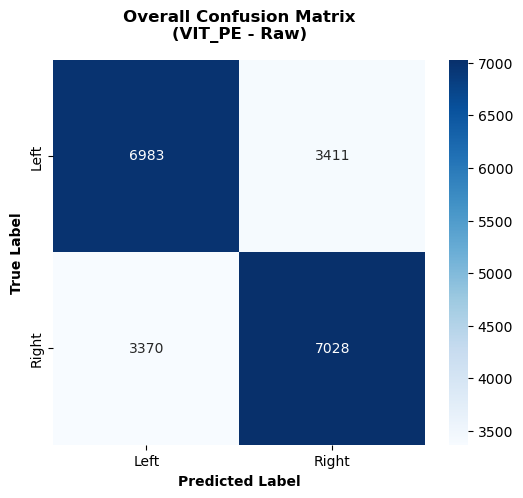

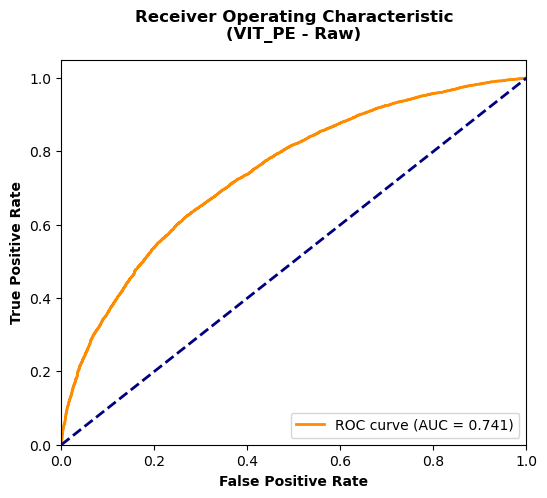

✅ Plots generated and saved successfully!


In [5]:
import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupKFold
from sklearn.metrics import confusion_matrix, roc_curve, auc
from tensorflow.keras.models import load_model
from tensorflow.keras.utils import Sequence
from tensorflow.keras.layers import Layer, Dense

# =========================
# 1. Initial Settings
# =========================
DATASET_NAME = "Raw"  
CSV_FILE = "dataset_metadata_raw.csv"

MODEL_PREFIX = "vit_pe"
BATCH_SIZE = 32
N_CLASSES = 2
SEQ_LEN = 2560
CHANNELS = 27

# =========================
# 2. Custom Layers for ViT-PE (Crucial for load_model)
# =========================
class Patches(Layer):
    def __init__(self, patch_size, **kwargs):
        super(Patches, self).__init__(**kwargs)
        self.patch_size = patch_size

    def call(self, signals):
        batch_size = tf.shape(signals)[0]
        patches = tf.reshape(signals, [batch_size, -1, self.patch_size, tf.shape(signals)[-1]])
        return patches

    def get_config(self):
        config = super(Patches, self).get_config()
        config.update({"patch_size": self.patch_size})
        return config

class PatchEncoder(Layer):
    def __init__(self, num_patches, projection_dim, **kwargs):
        super(PatchEncoder, self).__init__(**kwargs)
        self.num_patches = num_patches
        self.projection_dim = projection_dim
        self.projection = Dense(units=projection_dim)
        
        pos_encoding_matrix = self.get_sinusoidal_position_embedding(num_patches, projection_dim)
        self.position_embedding = tf.Variable(
            pos_encoding_matrix, trainable=False, name="position_embedding"
        )

    def get_sinusoidal_position_embedding(self, sequence_length, embedding_dim):
        angle_rates = 1.0 / (10000 ** (tf.range(0, embedding_dim, 2, dtype=tf.float32) / float(embedding_dim)))
        positions = tf.range(sequence_length, dtype=tf.float32)[:, tf.newaxis]
        angle_rads = positions * angle_rates[tf.newaxis, :]
        sines = tf.math.sin(angle_rads)
        cosines = tf.math.cos(angle_rads)
        pos_encoding = tf.concat([sines, cosines], axis=-1)
        return pos_encoding

    def call(self, patch):
        batch_size = tf.shape(patch)[0]
        patch_height = patch.shape[-2]
        patch_width = patch.shape[-1]
        
        patch_flattened = tf.reshape(patch, [batch_size, self.num_patches, patch_height * patch_width])
        encoded = self.projection(patch_flattened)
        encoded += self.position_embedding 
        return encoded

    def get_config(self):
        config = super(PatchEncoder, self).get_config()
        config.update({"num_patches": self.num_patches, "projection_dim": self.projection_dim})
        return config

# =========================
# 3. Data Generator (Shape: 2560, 27)
# =========================
class EEGGenerator_ViT(Sequence):
    def __init__(self, df, batch_size=32, shuffle=False):
        self.df = df.reset_index(drop=True)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indexes = np.arange(len(self.df))

    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch_size))

    def __getitem__(self, idx):
        batch_idx = self.indexes[idx * self.batch_size:(idx + 1) * self.batch_size]
        batch_df = self.df.iloc[batch_idx]

        X, y = [], []
        for _, row in batch_df.iterrows():
            data = np.load(row["file"])
            # ViT-PE expects exactly (2560, 27) - no transpose needed based on your original data shape
            X.append(data)
            y.append(row["label"])

        X = np.array(X, dtype=np.float32)
        y = tf.keras.utils.to_categorical(y, N_CLASSES)
        return X, y

# =========================
# 4. Load Data and Apply GroupKFold
# =========================
df = pd.read_csv(CSV_FILE)
gkf = GroupKFold(n_splits=5)
groups = df["subject"]

all_y_true = []
all_y_pred_probs = []
all_y_pred_classes = []

print(f"Evaluating {MODEL_PREFIX.upper()} on {DATASET_NAME}...")

for fold, (train_idx, val_idx) in enumerate(gkf.split(df, df["label"], groups)):
    print(f"Processing Fold {fold + 1}/5...")
    val_df = df.iloc[val_idx]
    val_gen = EEGGenerator_ViT(val_df, BATCH_SIZE, shuffle=False)
    
    model_path = f"models/{MODEL_PREFIX}_{DATASET_NAME}_fold{fold + 1}.h5"
    if not os.path.exists(model_path):
        print(f"⚠️ Error: Model file not found -> {model_path}")
        continue
        
    # ✅ Load model with Custom Objects specifically for ViT-PE
    model = load_model(
        model_path, 
        custom_objects={
            'Patches': Patches, 
            'PatchEncoder': PatchEncoder
        }
    )
    
    # Perform predictions
    for X_batch, y_batch in val_gen:
        preds = model.predict(X_batch, verbose=0)
        all_y_true.extend(np.argmax(y_batch, axis=1))
        all_y_pred_classes.extend(np.argmax(preds, axis=1))
        all_y_prob = preds[:, 1] # Probability of class 1 (Right Hand)
        all_y_pred_probs.extend(all_y_prob)
        
    del model
    tf.keras.backend.clear_session()
    gc.collect()

# =========================
# 5. Plot and Save Graphs
# =========================
os.makedirs("plots", exist_ok=True)

# ---- Confusion Matrix ----
cm = confusion_matrix(all_y_true, all_y_pred_classes)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Left', 'Right'], yticklabels=['Left', 'Right'])
plt.title(f'Overall Confusion Matrix\n({MODEL_PREFIX.upper()} - {DATASET_NAME})', pad=15, fontsize=12, fontweight='bold')
plt.ylabel('True Label', fontweight='bold')
plt.xlabel('Predicted Label', fontweight='bold')
plt.savefig(f'plots/CM_{MODEL_PREFIX}_{DATASET_NAME}.png', dpi=300, bbox_inches='tight')
plt.show()

# ---- ROC Curve ----
fpr, tpr, thresholds = roc_curve(all_y_true, all_y_pred_probs)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontweight='bold')
plt.ylabel('True Positive Rate', fontweight='bold')
plt.title(f'Receiver Operating Characteristic\n({MODEL_PREFIX.upper()} - {DATASET_NAME})', pad=15, fontsize=12, fontweight='bold')
plt.legend(loc="lower right")
plt.savefig(f'plots/ROC_{MODEL_PREFIX}_{DATASET_NAME}.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Plots generated and saved successfully!")

Evaluating VIT_PE on Filtered_8_30Hz...
Processing Fold 1/5...
Processing Fold 2/5...
Processing Fold 3/5...
Processing Fold 4/5...
Processing Fold 5/5...


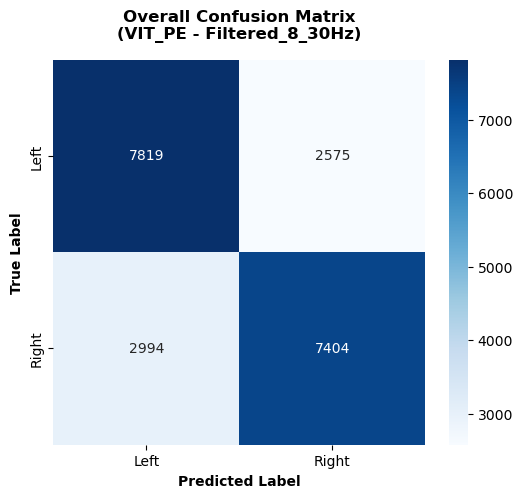

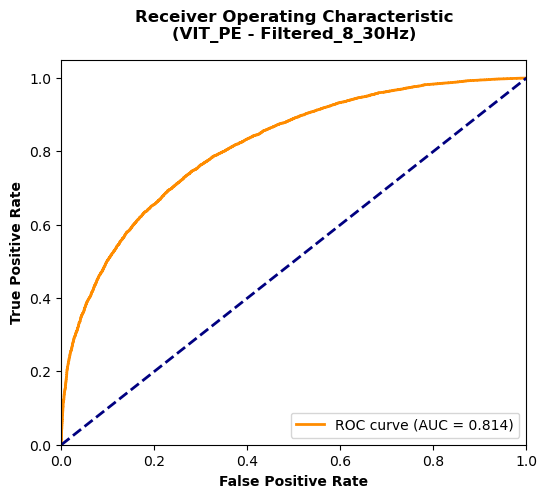

✅ Plots generated and saved successfully!


In [6]:
import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupKFold
from sklearn.metrics import confusion_matrix, roc_curve, auc
from tensorflow.keras.models import load_model
from tensorflow.keras.utils import Sequence
from tensorflow.keras.layers import Layer, Dense

# =========================
# 1. Initial Settings
# =========================
DATASET_NAME = "Filtered_8_30Hz"  
CSV_FILE = "dataset_metadata_filtered.csv"

MODEL_PREFIX = "vit_pe"
BATCH_SIZE = 32
N_CLASSES = 2
SEQ_LEN = 2560
CHANNELS = 27

# =========================
# 2. Custom Layers for ViT-PE (Crucial for load_model)
# =========================
class Patches(Layer):
    def __init__(self, patch_size, **kwargs):
        super(Patches, self).__init__(**kwargs)
        self.patch_size = patch_size

    def call(self, signals):
        batch_size = tf.shape(signals)[0]
        patches = tf.reshape(signals, [batch_size, -1, self.patch_size, tf.shape(signals)[-1]])
        return patches

    def get_config(self):
        config = super(Patches, self).get_config()
        config.update({"patch_size": self.patch_size})
        return config

class PatchEncoder(Layer):
    def __init__(self, num_patches, projection_dim, **kwargs):
        super(PatchEncoder, self).__init__(**kwargs)
        self.num_patches = num_patches
        self.projection_dim = projection_dim
        self.projection = Dense(units=projection_dim)
        
        pos_encoding_matrix = self.get_sinusoidal_position_embedding(num_patches, projection_dim)
        self.position_embedding = tf.Variable(
            pos_encoding_matrix, trainable=False, name="position_embedding"
        )

    def get_sinusoidal_position_embedding(self, sequence_length, embedding_dim):
        angle_rates = 1.0 / (10000 ** (tf.range(0, embedding_dim, 2, dtype=tf.float32) / float(embedding_dim)))
        positions = tf.range(sequence_length, dtype=tf.float32)[:, tf.newaxis]
        angle_rads = positions * angle_rates[tf.newaxis, :]
        sines = tf.math.sin(angle_rads)
        cosines = tf.math.cos(angle_rads)
        pos_encoding = tf.concat([sines, cosines], axis=-1)
        return pos_encoding

    def call(self, patch):
        batch_size = tf.shape(patch)[0]
        patch_height = patch.shape[-2]
        patch_width = patch.shape[-1]
        
        patch_flattened = tf.reshape(patch, [batch_size, self.num_patches, patch_height * patch_width])
        encoded = self.projection(patch_flattened)
        encoded += self.position_embedding 
        return encoded

    def get_config(self):
        config = super(PatchEncoder, self).get_config()
        config.update({"num_patches": self.num_patches, "projection_dim": self.projection_dim})
        return config

# =========================
# 3. Data Generator (Shape: 2560, 27)
# =========================
class EEGGenerator_ViT(Sequence):
    def __init__(self, df, batch_size=32, shuffle=False):
        self.df = df.reset_index(drop=True)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indexes = np.arange(len(self.df))

    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch_size))

    def __getitem__(self, idx):
        batch_idx = self.indexes[idx * self.batch_size:(idx + 1) * self.batch_size]
        batch_df = self.df.iloc[batch_idx]

        X, y = [], []
        for _, row in batch_df.iterrows():
            data = np.load(row["file"])
            # ViT-PE expects exactly (2560, 27) - no transpose needed based on your original data shape
            X.append(data)
            y.append(row["label"])

        X = np.array(X, dtype=np.float32)
        y = tf.keras.utils.to_categorical(y, N_CLASSES)
        return X, y

# =========================
# 4. Load Data and Apply GroupKFold
# =========================
df = pd.read_csv(CSV_FILE)
gkf = GroupKFold(n_splits=5)
groups = df["subject"]

all_y_true = []
all_y_pred_probs = []
all_y_pred_classes = []

print(f"Evaluating {MODEL_PREFIX.upper()} on {DATASET_NAME}...")

for fold, (train_idx, val_idx) in enumerate(gkf.split(df, df["label"], groups)):
    print(f"Processing Fold {fold + 1}/5...")
    val_df = df.iloc[val_idx]
    val_gen = EEGGenerator_ViT(val_df, BATCH_SIZE, shuffle=False)
    
    model_path = f"models/{MODEL_PREFIX}_{DATASET_NAME}_fold{fold + 1}.h5"
    if not os.path.exists(model_path):
        print(f"⚠️ Error: Model file not found -> {model_path}")
        continue
        
    # ✅ Load model with Custom Objects specifically for ViT-PE
    model = load_model(
        model_path, 
        custom_objects={
            'Patches': Patches, 
            'PatchEncoder': PatchEncoder
        }
    )
    
    # Perform predictions
    for X_batch, y_batch in val_gen:
        preds = model.predict(X_batch, verbose=0)
        all_y_true.extend(np.argmax(y_batch, axis=1))
        all_y_pred_classes.extend(np.argmax(preds, axis=1))
        all_y_prob = preds[:, 1] # Probability of class 1 (Right Hand)
        all_y_pred_probs.extend(all_y_prob)
        
    del model
    tf.keras.backend.clear_session()
    gc.collect()

# =========================
# 5. Plot and Save Graphs
# =========================
os.makedirs("plots", exist_ok=True)

# ---- Confusion Matrix ----
cm = confusion_matrix(all_y_true, all_y_pred_classes)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Left', 'Right'], yticklabels=['Left', 'Right'])
plt.title(f'Overall Confusion Matrix\n({MODEL_PREFIX.upper()} - {DATASET_NAME})', pad=15, fontsize=12, fontweight='bold')
plt.ylabel('True Label', fontweight='bold')
plt.xlabel('Predicted Label', fontweight='bold')
plt.savefig(f'plots/CM_{MODEL_PREFIX}_{DATASET_NAME}.png', dpi=300, bbox_inches='tight')
plt.show()

# ---- ROC Curve ----
fpr, tpr, thresholds = roc_curve(all_y_true, all_y_pred_probs)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontweight='bold')
plt.ylabel('True Positive Rate', fontweight='bold')
plt.title(f'Receiver Operating Characteristic\n({MODEL_PREFIX.upper()} - {DATASET_NAME})', pad=15, fontsize=12, fontweight='bold')
plt.legend(loc="lower right")
plt.savefig(f'plots/ROC_{MODEL_PREFIX}_{DATASET_NAME}.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Plots generated and saved successfully!")

Evaluating VIT_PE on Filtered_8_13Hz...
Processing Fold 1/5...
Processing Fold 2/5...
Processing Fold 3/5...
Processing Fold 4/5...
Processing Fold 5/5...


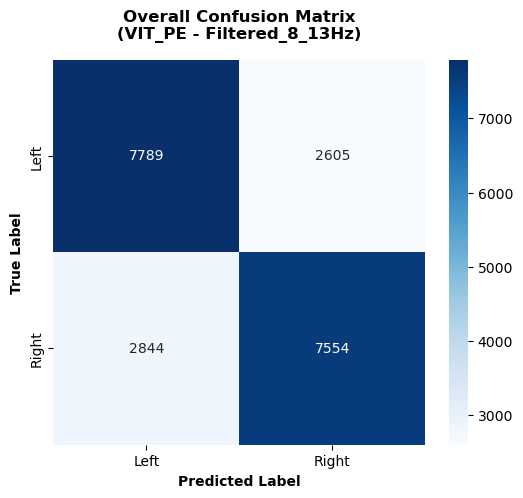

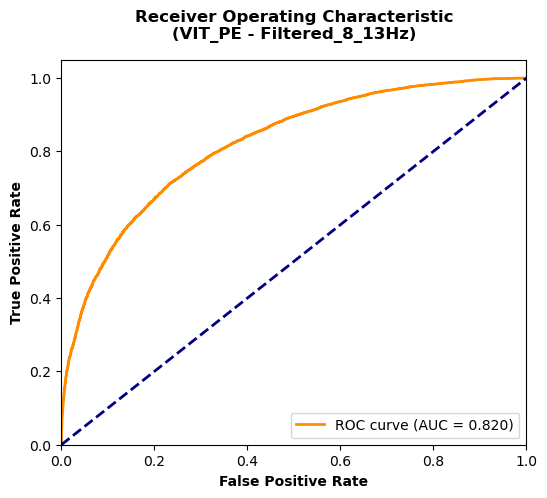

✅ Plots generated and saved successfully!


In [7]:
import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupKFold
from sklearn.metrics import confusion_matrix, roc_curve, auc
from tensorflow.keras.models import load_model
from tensorflow.keras.utils import Sequence
from tensorflow.keras.layers import Layer, Dense

# =========================
# 1. Initial Settings
# =========================
DATASET_NAME = "Filtered_8_13Hz"  
CSV_FILE = "dataset_metadata_8_13Hz.csv"

MODEL_PREFIX = "vit_pe"
BATCH_SIZE = 16
N_CLASSES = 2
SEQ_LEN = 2560
CHANNELS = 27

# =========================
# 2. Custom Layers for ViT-PE (Crucial for load_model)
# =========================
class Patches(Layer):
    def __init__(self, patch_size, **kwargs):
        super(Patches, self).__init__(**kwargs)
        self.patch_size = patch_size

    def call(self, signals):
        batch_size = tf.shape(signals)[0]
        patches = tf.reshape(signals, [batch_size, -1, self.patch_size, tf.shape(signals)[-1]])
        return patches

    def get_config(self):
        config = super(Patches, self).get_config()
        config.update({"patch_size": self.patch_size})
        return config

class PatchEncoder(Layer):
    def __init__(self, num_patches, projection_dim, **kwargs):
        super(PatchEncoder, self).__init__(**kwargs)
        self.num_patches = num_patches
        self.projection_dim = projection_dim
        self.projection = Dense(units=projection_dim)
        
        pos_encoding_matrix = self.get_sinusoidal_position_embedding(num_patches, projection_dim)
        self.position_embedding = tf.Variable(
            pos_encoding_matrix, trainable=False, name="position_embedding"
        )

    def get_sinusoidal_position_embedding(self, sequence_length, embedding_dim):
        angle_rates = 1.0 / (10000 ** (tf.range(0, embedding_dim, 2, dtype=tf.float32) / float(embedding_dim)))
        positions = tf.range(sequence_length, dtype=tf.float32)[:, tf.newaxis]
        angle_rads = positions * angle_rates[tf.newaxis, :]
        sines = tf.math.sin(angle_rads)
        cosines = tf.math.cos(angle_rads)
        pos_encoding = tf.concat([sines, cosines], axis=-1)
        return pos_encoding

    def call(self, patch):
        batch_size = tf.shape(patch)[0]
        patch_height = patch.shape[-2]
        patch_width = patch.shape[-1]
        
        patch_flattened = tf.reshape(patch, [batch_size, self.num_patches, patch_height * patch_width])
        encoded = self.projection(patch_flattened)
        encoded += self.position_embedding 
        return encoded

    def get_config(self):
        config = super(PatchEncoder, self).get_config()
        config.update({"num_patches": self.num_patches, "projection_dim": self.projection_dim})
        return config

# =========================
# 3. Data Generator (Shape: 2560, 27)
# =========================
class EEGGenerator_ViT(Sequence):
    def __init__(self, df, batch_size=32, shuffle=False):
        self.df = df.reset_index(drop=True)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indexes = np.arange(len(self.df))

    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch_size))

    def __getitem__(self, idx):
        batch_idx = self.indexes[idx * self.batch_size:(idx + 1) * self.batch_size]
        batch_df = self.df.iloc[batch_idx]

        X, y = [], []
        for _, row in batch_df.iterrows():
            data = np.load(row["file"])
            # ViT-PE expects exactly (2560, 27) - no transpose needed based on your original data shape
            X.append(data)
            y.append(row["label"])

        X = np.array(X, dtype=np.float32)
        y = tf.keras.utils.to_categorical(y, N_CLASSES)
        return X, y

# =========================
# 4. Load Data and Apply GroupKFold
# =========================
df = pd.read_csv(CSV_FILE)
gkf = GroupKFold(n_splits=5)
groups = df["subject"]

all_y_true = []
all_y_pred_probs = []
all_y_pred_classes = []

print(f"Evaluating {MODEL_PREFIX.upper()} on {DATASET_NAME}...")

for fold, (train_idx, val_idx) in enumerate(gkf.split(df, df["label"], groups)):
    print(f"Processing Fold {fold + 1}/5...")
    val_df = df.iloc[val_idx]
    val_gen = EEGGenerator_ViT(val_df, BATCH_SIZE, shuffle=False)
    
    model_path = f"models/{MODEL_PREFIX}_{DATASET_NAME}_fold{fold + 1}.h5"
    if not os.path.exists(model_path):
        print(f"⚠️ Error: Model file not found -> {model_path}")
        continue
        
    # ✅ Load model with Custom Objects specifically for ViT-PE
    model = load_model(
        model_path, 
        custom_objects={
            'Patches': Patches, 
            'PatchEncoder': PatchEncoder
        }
    )
    
    # Perform predictions
    for X_batch, y_batch in val_gen:
        preds = model.predict(X_batch, verbose=0)
        all_y_true.extend(np.argmax(y_batch, axis=1))
        all_y_pred_classes.extend(np.argmax(preds, axis=1))
        all_y_prob = preds[:, 1] # Probability of class 1 (Right Hand)
        all_y_pred_probs.extend(all_y_prob)
        
    del model
    tf.keras.backend.clear_session()
    gc.collect()

# =========================
# 5. Plot and Save Graphs
# =========================
os.makedirs("plots", exist_ok=True)

# ---- Confusion Matrix ----
cm = confusion_matrix(all_y_true, all_y_pred_classes)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Left', 'Right'], yticklabels=['Left', 'Right'])
plt.title(f'Overall Confusion Matrix\n({MODEL_PREFIX.upper()} - {DATASET_NAME})', pad=15, fontsize=12, fontweight='bold')
plt.ylabel('True Label', fontweight='bold')
plt.xlabel('Predicted Label', fontweight='bold')
plt.savefig(f'plots/CM_{MODEL_PREFIX}_{DATASET_NAME}.png', dpi=300, bbox_inches='tight')
plt.show()

# ---- ROC Curve ----
fpr, tpr, thresholds = roc_curve(all_y_true, all_y_pred_probs)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontweight='bold')
plt.ylabel('True Positive Rate', fontweight='bold')
plt.title(f'Receiver Operating Characteristic\n({MODEL_PREFIX.upper()} - {DATASET_NAME})', pad=15, fontsize=12, fontweight='bold')
plt.legend(loc="lower right")
plt.savefig(f'plots/ROC_{MODEL_PREFIX}_{DATASET_NAME}.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Plots generated and saved successfully!")